In [1]:
%load_ext autoreload
%autoreload 2

In [1]:
import os
import numpy as np
import matplotlib.pylab as plt
import time
from datetime import datetime

import sys
import imp
import pickle

sys.path.insert(0,'../main_scripts')
import run_analysis_funcs as raf
import run_config_funcs as rcf

#
#exp_name = 'shelf_demo'
# exp_name = 'shelf_demo_50kmres'
# exp_name = 'shelf_drake_ridge_H3km_v02_noaabw'
# exp_name = 'shelf_drake_ridge_noise_H3km_v02_noaabw'
# exp_name = 'shelf_nodrake_ridge_H3km_v02_noaabw'
# exp_name = 'shelf_nodrake_circumpolarridge_H3km_v02_noaabw'
# exp_name = 'shelf_drake_ridge_H3km_v02_noaabw_branch01_neg25pct_wgb'
# exp_name = 'shelf_drake_ridge_noise_H3km_v02_noaabw_max150msimplex'
# exp_name = 'shelf_drake_ridge_noise_white_blocks_smootherNz_H3km_v02_noaabw'
# exp_name = 'shelf_drake_ridge_noise_H3km_v02_testaabw_branch01_1yearoutputs'
# exp_name = 'shelf_drake_noridge_noise_H3km_v02_noaabw'
# exp_name = 'shelf_drake_ridge_seamountzrt_noise_H3km_v02_noaabw'
# exp_name = 'shelf_drake_noridge_noise_H3km_v02_noaabw_branch01_25pct_wgb_y1500km'
# exp_name = 'shelf_drake_ridge_seamountzrt_noise_H3km_v02_noaabw_branch01_sin2_nospongeforce'
# exp_name = 'shelf_drake_ridge_seamountzrt_noise_H3km_v02_noaabw_branch03_sww15north_pe1no0atSB_nospongeforce'
# exp_name = 'shelf_drake_ridge_nocontinent_H3km_v02_noaabw'
# exp_name = 'shelf_drake_longridge_nocontinent_H3km_v02_noaabw'
# exp_name = 'shelf_drake_longridge_nocontinent_H3km_v02_noaabw_branch01_increasterly'
# exp_name = 'shelf_drake_curvedshortridge_nocontinent_H3km_v02_noaabw'
# exp_name = 'shelf_drake500_curvedshortridge_nocontinent_H3km_v02_noaabw'
# exp_name = 'shelf_drake500_curvedshortridge500_nocontinent_H3km_v02_noaabw'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_H3km_v02_noaabw'
# exp_name = 'shelf_drake_MRgap_nocontinent_H3km_v02_noaabw'
# exp_name = 'shelf_drake500_ramp2ridge500_smallabyssalplain_nocontinent_H3km_v02_noaabw'
# exp_name='shelf_drake1500_ramp2ridge1500_linearramps_nocontinent_H3km_v02_noaabw'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_H3km_v02_noaabw_branch01_decr_wsc_SG_nolayers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise_noMR_H3km_v02_noaabw'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw'
# exp_name = 'shelf_H3km_v02_noaabw'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_branch01_incr_wsc_SG_layers'
# exp_name = 'shelf_H3km_v02_noaabw_branch01_layers'
# exp_name = 'shelf_H3km_v02_noaabw_branch01_25pct_wgb_y1250km_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_H3km_v02_noaabw'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_branch01_year200_layers'
# exp_name = 'shelf_drake500_nocontinent_H3km_v02_noaabw'
# exp_name = 'shelf_drake500_nocontinent_H3km_v02_noaabw_branch01_contract2_both_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_H3km_v02_noaabw_fixZR_80Nz'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_H3km_v02_noaabw_fixZR_80Nz_branch01_25pct_wgb_y1250km_year200_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_H3km_v02_noaabw_fixZR_80Nz_branch01_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_H3km_v02_noaabw_fixZR_80Nz_branch01_contract2_south_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_H3km_v02_noaabw_branch01_incr_wsc_SG_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_H3km_v02_noaabw_branch01_contract2_both_year250_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_branch01_year200_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_branch01_incr_wsc_SG_year200_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_branch01_25pct_wgb_y1250km_year200_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_branch01_contract2_both_year200_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_branch01_25pct_wgb_y1000km_year200_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_branch01_25pct_wgb_y1500km_year200_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun'
# exp_name = 'shelf_H3km_v02_noaabw_branch01_incr_wsc_SG_subpolarONLYfixMag_year250_layers'
# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_all3_year200_layers'
# exp_name = 'shelf_H3km_v02_noaabw_branch01_25pct_wgb_y1375km_year250_layers'
exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_25pct_egb_centered_year200_layers'

# exp_name = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_2Lx'

In [2]:
SUNet_ID = os.environ['HOME'].split('/')[-1]
# os.environ['GROUP_SCRATCH'] 
scratch_dir = '/scratch/groups/earlew'#os.environ['GROUP_SCRATCH']  #'/oak/stanford/groups/earlew'#
exp_dir = os.path.join(scratch_dir, SUNet_ID, 'research/modeling/MITgcm/experiments/')   

exp_path = os.path.join(exp_dir, exp_name)

In [3]:
exp_path

'/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_25pct_egb_centered_year200_layers'

In [4]:
# check for last pickup file (the script can only extend from a pickup file)
imp.reload(raf)
imp.reload(rcf)
secsInYr = 3600*24*365
params,_ = raf.get_exp_params_py(exp_path, add_hFac=False)
#lastIter = rcf.getLastPickupIter(params['results_path'])
lastIter = rcf.getLastPickupIter(os.path.join(exp_path, 'results'))
pickupSec = int(lastIter)*params['deltaT']
pickupYear = pickupSec/secsInYr
print(lastIter)
print(pickupSec)
print(pickupYear)

0006442492
6307199668.0
199.99998947234906


In [5]:
params['results_path']

'/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_25pct_egb_centered_year200_layers/results'

In [6]:
# get list of saved iterations
imp.reload(raf)
iters = rcf.getSavedIters(vname='THETA_inst', results_path = params['results_path'])
iters

array([6442492, 6442934, 6443375, 6443816, 6444257, 6444699, 6445140,
       6445581, 6446022, 6446464, 6446905, 6447346, 6447788, 6448229,
       6448670, 6449111, 6449553, 6449994, 6450435, 6450876, 6451318,
       6451759, 6452200, 6452641, 6453083, 6453524, 6453965, 6454407,
       6454848, 6455289, 6455730, 6456172, 6456613, 6457054, 6457495,
       6457937, 6458378, 6458819, 6459260, 6459702, 6460143, 6460584,
       6461026, 6461467, 6461908, 6462349, 6462791, 6463232, 6463673,
       6464114, 6464556, 6464997, 6465438, 6465879, 6466321, 6466762,
       6467203, 6467645, 6468086, 6468527, 6468968, 6469410, 6469851,
       6470292, 6470733, 6471175, 6471616, 6472057, 6472498, 6472940,
       6473381, 6473822, 6474264, 6474705, 6475146, 6475587, 6476029,
       6476470, 6476911, 6477352, 6477794, 6478235, 6478676, 6479117,
       6479559, 6480000, 6480441, 6480883, 6481324, 6481765, 6482206,
       6482648, 6483089, 6483530, 6483971, 6484413, 6484854, 6485295,
       6485736, 6486

In [7]:
# get run times

# get creation time of output files
vble_name = 'THETA_inst'
results_files = os.listdir(params['results_path'])
vble_files = [f for f in results_files if f.startswith(vble_name) and f.endswith('.data')]
vble_files.sort()

# # Niall edits just once
# vble_files = vble_files[1:]

time_stmps = np.array([os.path.getctime(os.path.join(params['results_path'], f)) for f in vble_files])

# offset time stamp
time_stmps = time_stmps-time_stmps[0] # note: os.path.getctime rounds to nearest second

# remove negative wall time values
time_stmps[time_stmps<0] = np.nan

# get model time 
iters = np.array([int(f.split('.')[1]) for f in vble_files])
model_time = iters*params['deltaT']
model_time_yrs = model_time/secsInYr

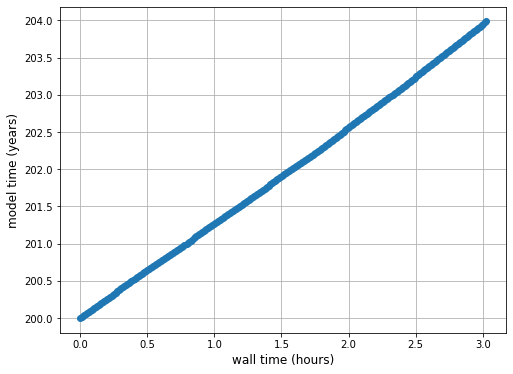

In [8]:
plt.figure(figsize=(8, 6))
fz = 12
plt.plot(time_stmps/3600, model_time/secsInYr, '-o')
plt.ylabel("model time (years)", fontsize=fz)
plt.xlabel("wall time (hours)", fontsize=fz)
plt.grid(True)

# plt.plot(time_stmps, model_time, '-o')
# plt.ylabel("model time (seconds)", fontsize=fz)
# plt.xlabel("wall time (seconds)", fontsize=fz)
# plt.grid(True)

In [9]:
time_stmps

array([   0.,   60.,  124.,  191.,  257.,  319.,  365.,  433.,  485.,
        531.,  577.,  625.,  672.,  732.,  772.,  813.,  857.,  898.,
        937., 1002., 1046., 1087., 1131., 1185., 1228., 1284., 1328.,
       1368., 1409., 1452., 1493., 1549., 1589., 1633., 1673., 1714.,
       1759., 1818., 1861.])

In [10]:
# Note: run this out for at least year before trying to extrapolate 

dump_range = 10 # use last few runs to compute efficiency
time_stmps_hrs = time_stmps/3600

dt_wallclock = time_stmps_hrs[-1] - time_stmps_hrs[-dump_range]
dt_model = model_time_yrs[-1] - model_time_yrs[-dump_range]

run_eff_yrs_hr = dt_model/dt_wallclock
print("Model efficiency: %.5f model years per wall clock hours" %run_eff_yrs_hr.mean())

Model efficiency: 1.08508 model years per wall clock hours


In [11]:
# alternatively 
wall_mins_per_sim_yr = 60/run_eff_yrs_hr.mean()
print("Model efficiency: %.2f wall clock minutes per model year" %wall_mins_per_sim_yr.mean())

Model efficiency: 55.30 wall clock minutes per model year


In [12]:
# print current run_mitgcm script
with open(os.path.join(params['results_path'], 'run_mitgcm'), 'r') as f:
          print(f.read())

#!/bin/bash 
#SBATCH -J shelf_H3km_v02_noaabw_branch01_25pct_wgb_y1375km_year250_layers
#SBATCH -o output_%j.txt # output and error file name (%j expands to jobID)
#SBATCH -n 250   #total number of mpi tasks requested
##SBATCH --nodes=13   #total number of nodes requested
#SBATCH --constraint=CLASS:SH3_CBASE
#SBATCH --mem-per-cpu=250M
#SBATCH -p serc
#SBATCH -t 24:00:00  # run time (hh:mm:ss)
#SBATCH --mail-user=nbcoffey@stanford.edu
#SBATCH --mail-type=begin  # email me when the job starts
#SBATCH --mail-type=end  # email me when the job finishes

module load netcdf
module load openmpi/4.0.3
#module load openmpi
srun ./mitgcmuv



In [14]:
imp.reload(rcf)

ncpus = params['grid_params']['nPx']*params['grid_params']['nPy']

endyr = 280 #230

# endyr
rcf.extendRun(exp_path, newEndYr=endyr, overWriteFiles=True, printNewRunScript=True, results_path='', ncpus=ncpus,
              wall_mins_per_sim_yr=wall_mins_per_sim_yr*1.1, max_walltime_hrs=72)

# endyr + 10
# rcf.extendRun(exp_path, newEndYr=endyr+10, overWriteFiles=True, printNewRunScript=True, results_path='', ncpus=ncpus,
#               wall_mins_per_sim_yr=wall_mins_per_sim_yr*1.1, max_walltime_hrs=72)

# set overWriteFiles=True, when you're ready to create new

Backing up data...
Backing up params.p...
Backing up data.diagnostics...
Backing up run_mitgcm...
Estimated runtime: 32.0 hrs
--------------------

---------------------------------
#!/bin/bash 
#SBATCH -J shelf_H3km_v02_noaabw_branch01_25pct_wgb_y1375km_year250_layers
#SBATCH -o output_%j.txt # output and error file name (%j expands to jobID)
#SBATCH -n 250   #total number of mpi tasks requested
##SBATCH --nodes=13   #total number of nodes requested
#SBATCH --constraint=CLASS:SH3_CBASE
#SBATCH --mem-per-cpu=250M
#SBATCH -p serc
#SBATCH -t 32:00:00  # run time (hh:mm:ss)
#SBATCH --mail-user=nbcoffey@stanford.edu
#SBATCH --mail-type=begin  # email me when the job starts
#SBATCH --mail-type=end  # email me when the job finishes

module load netcdf
module load openmpi/4.0.3
#module load openmpi
srun ./mitgcmuv

---------------------------------
run_mitgcm updated!
Ready to submit...
Over-writing data and param files!


In [15]:
exp_path

'/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/shelf_H3km_v02_noaabw_branch01_25pct_wgb_y1375km_year250_layers'